## Module 2: FSHD Clinical Trial Project Template

Complete the sections below as a team. Remove the word “Template” only if it appears in the final notebook title.

## Project Goal:

This project uses natural-history data from 34 individuals with facioscapulohumeral muscular dystrophy (FSHD), followed longitudinally over approximately two years, to evaluate candidate measures of disease progression. These include MRI-derived fat fraction and inflammation, dorsiflexion strength, functional performance tests, and clinical severity score. Following interpolation of irregular visit intervals onto a common timeline, each measure will be compared on sensitivity to change, inter-patient consistency, feasibility, and clinical relevance. The analysis will culminate in a recommendation of which measures should be included as exploratory endpoints in an early-phase (Phase 1/2) clinical trial of a novel FSHD therapy.

## Disease Background: 


### Prevalence & incidence

Facioscapulohumeral muscular dystrophy (FSH) is a genetic disease that causes progressive weakening of skeletal muscle. FSH affects about 4 in every 100,000 people. 

https://www.urmc.rochester.edu/conditions-and-treatments/facioscapulohumeral-muscular-dystrophy 

### Symptoms

Symptoms of FSH often include muscle facial weakness, shoulder weakness, lower leg weakness, abdominal weakness, posture changes, and chronic pain and inflammation affecting the shoulders, neck, legs, and back.

https://www.mda.org/disease/facioscapulohumeral-muscular-dystrophy/signs-and-symptoms 

### Diagnosis

To diagnose FSH, doctors often run a series of tests including a blood test, neurological test, and a muscle biopsy. Doctors are specifically looking for muscle abnormalities during a biopsy and for specific blood enzymes, specifically serum creatine kinase (CK), an enzyme that is released into the blood stream when muscles start to deteriorate. To officially confirm an FSH diagnosis, a genetic test is required.

https://www.fshdsociety.org/living-with-fshd/understanding-fshd/diagnosis/ 

### Standard of care treatments (& reimbursement) 

There is no cure for FSH, however healthcare providers often recommend physical therapy, orthotic devices and braces to support weak muscles, and sometimes surgical intervention. 

https://my.clevelandclinic.org/health/diseases/facioscapulohumeral-muscular-dystrophy-fshd 

### Disease progression & prognosis

Progression of FSH is nonlinear and variable from person to person, however most people with FSH can expect to live normal lifespans. However, some health issues may arise, including chronic pain, respiratory muscle difficulties or failure (uncommon), and other rare complications. Progression of the disease is typically slow and unpredictable. About 20% of people with FSH are wheelchair dependent.

https://www.sciencedirect.com/science/article/pii/S096089662600057X?__cf_chl_tk=CIgVRcGRWtwRWJuinNRvVYItpkjZlnPQAnesPHOAWjQ-1792107882-1.0.1.1-fslch.IFwagT.xzuBn_e_LBOuGKWDrGRP_RN23qaELc 

https://pmc.ncbi.nlm.nih.gov/articles/PMC4520817/ 

https://my.clevelandclinic.org/health/diseases/facioscapulohumeral-muscular-dystrophy-fshd 

### Biological mechanisms (anatomy, organ physiology, cell & molecular physiology)

There are two types of FSH, separated into Type 1 and Type 2 and both cause the same symptoms. FSH1 accounts for 95% of cases and occurs when the DUX4 gene that is supposed to be inactivated becomes activated. The reactivation of DUX4 is known to initiate the production of proteins that destroy muscle cells. FSH2 accounts for the remaining 5% of cases and occurs when a different gene mutates or changes to turn on DUX4. As muscle fibers break down, healthy muscle is replaced by fat and scar tissue. The nuclei in muscle cells travels from the outside of the cell to the middle to coordinate cellular rebuilding. 

https://www.sciencedirect.com/science/article/pii/S096089662600057X?__cf_chl_tk=CIgVRcGRWtwRWJuinNRvVYItpkjZlnPQAnesPHOAWjQ-1792107882-1.0.1.1-fslch.IFwagT.xzuBn_e_LBOuGKWDrGRP_RN23qaELc 

### Clinical Trials/next-gen therapies

There is no FDA approved treatment for FSH. Most current clinical trials and therapies in development focus on controlling the expression of the DUX4 gene or reducing the harm of its expression. Most therapies are in phase 1 or 2 and focus on DUX4 expression using various antibody therapies, mRNA and RNA regimenes, and specific inhibition treatments of various proteins.

Specific information about clinical trials was researched using a Consensus AI Pro subscription through the UVA library
https://consensus.app/search/fshd-clinical-trials-development/OTO7c9uoRCijwKJF7dxTYQ/?utm_source=share&utm_medium=clipboard 


## MRI Data Analysis Methodology:

Subject UW_0020, left tibialis anterior (TA), two visits (TP1 and TP2), eight cross-sectional samples per visit at locations 10% to 80% along the muscle. Each sample has a water image, a fat image, and a binary TA mask stored as NumPy arrays (266 x 224 pixels). `slice_info.csv` links each sample to its visit, percent location, and distance from the muscle start in mm.

The analysis has six steps: (1) load the metadata and the water, fat, and mask arrays; (2) compute fat fraction for each pixel; (3) use the mask to isolate the TA; (4) summarize the fat-fraction distribution (mean, median, SD, number of muscle pixels) for the whole image region and for the TA only; (5) repeat for all eight locations in each visit to build a profile along the muscle; (6) compare the two visits at matching percent locations and save a summary CSV.

### 1. Load the metadata and the image arrays

In [19]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

matches = list(Path.cwd().rglob("slice_info.csv"))
print("Found:", matches)
if not matches:
    raise FileNotFoundError("Could not find slice_info.csv. Put the data folder inside your project folder.")
DATA_DIR = matches[0].parent
manifest = pd.read_csv(DATA_DIR / "slice_info.csv")
manifest

Found: [PosixPath('/Users/skylarfalkner/Desktop/BME-2315-Module1/BME2315_Module2-fixed-/FSHD_MRI_data/FSHD_TA_MRI_data_0020_TP1_TP2/slice_info.csv')]


,subject,timepoint,slice_id,percent_along_muscle,z_index,distance_from_muscle_start_mm,water_file,fat_file,mask_file
0,UW_0020,TP1,1,10,41,24.0,TP1_slice_01_water.npy,TP1_slice_01_fat.npy,TP1_slice_01_mask.npy
1,UW_0020,TP1,2,20,46,44.0,TP1_slice_02_water.npy,TP1_slice_02_fat.npy,TP1_slice_02_mask.npy
2,UW_0020,TP1,3,30,52,68.0,TP1_slice_03_water.npy,TP1_slice_03_fat.npy,TP1_slice_03_mask.npy
3,UW_0020,TP1,4,40,58,92.0,TP1_slice_04_water.npy,TP1_slice_04_fat.npy,TP1_slice_04_mask.npy
4,UW_0020,TP1,5,50,64,116.0,TP1_slice_05_water.npy,TP1_slice_05_fat.npy,TP1_slice_05_mask.npy
5,UW_0020,TP1,6,60,69,136.0,TP1_slice_06_water.npy,TP1_slice_06_fat.npy,TP1_slice_06_mask.npy
6,UW_0020,TP1,7,70,75,160.0,TP1_slice_07_water.npy,TP1_slice_07_fat.npy,TP1_slice_07_mask.npy
7,UW_0020,TP1,8,80,81,184.0,TP1_slice_08_water.npy,TP1_slice_08_fat.npy,TP1_slice_08_mask.npy
8,UW_0020,TP2,1,10,40,24.0,TP2_slice_01_water.npy,TP2_slice_01_fat.npy,TP2_slice_01_mask.npy
9,UW_0020,TP2,2,20,46,48.0,TP2_slice_02_water.npy,TP2_slice_02_fat.npy,TP2_slice_02_mask.npy


Each row of the manifest names the water, fat, and mask files that belong together. The mask is converted to a boolean array (True = TA pixel).

In [20]:
row = manifest[manifest["timepoint"] == "TP1"].iloc[3]   # TP1, slice 04 (40% along muscle)

water = np.load(DATA_DIR / row["water_file"])
fat = np.load(DATA_DIR / row["fat_file"])
mask = np.load(DATA_DIR / row["mask_file"]).astype(bool)

print("Water image shape:", water.shape)
print("Fat image shape:", fat.shape)
print("Mask shape:", mask.shape)
print("Number of muscle pixels:", mask.sum())

Water image shape: (266, 224)
Fat image shape: (266, 224)
Mask shape: (266, 224)
Number of muscle pixels: 360


### 2 and 3. Compute fat fraction and isolate the TA

For each pixel: **fat fraction (%) = fat signal / (water signal + fat signal) x 100.** The ratio is only calculated where the denominator is greater than zero, so empty pixels do not cause division by zero. The **whole image region** statistics use every pixel with signal in the supplied image half (other muscle, subcutaneous fat, bone, background). For the **TA-only** statistics, pixels outside the mask are set to NaN so they are ignored by the mean, median, and histogram.

In [21]:
denominator = water + fat
valid_pixels = denominator > 0

fat_fraction = np.divide(fat, denominator,
                         out=np.zeros_like(fat, dtype=float),
                         where=valid_pixels) * 100

fat_fraction_full = fat_fraction.copy()          # whole supplied image region
fat_fraction_masked = fat_fraction.copy()
fat_fraction_masked[~mask] = np.nan              # TA only

whole_image_values = fat_fraction_full[valid_pixels]
muscle_values = fat_fraction_masked[~np.isnan(fat_fraction_masked)]

print(f"Whole supplied image region - mean: {np.mean(whole_image_values):.1f}%")
print(f"Whole supplied image region - minimum: {np.min(whole_image_values):.1f}%")
print(f"Whole supplied image region - maximum: {np.max(whole_image_values):.1f}%")
print()
print(f"TA muscle only - mean: {np.mean(muscle_values):.1f}%")
print(f"TA muscle only - median: {np.median(muscle_values):.1f}%")
print(f"TA muscle only - SD: {np.std(muscle_values):.1f}%")
print(f"TA muscle only - minimum: {np.min(muscle_values):.1f}%")
print(f"TA muscle only - maximum: {np.max(muscle_values):.1f}%")
print(f"TA muscle only - number of pixels: {muscle_values.size}")

Whole supplied image region - mean: 48.6%
Whole supplied image region - minimum: 0.0%
Whole supplied image region - maximum: 100.0%

TA muscle only - mean: 29.9%
TA muscle only - median: 25.4%
TA muscle only - SD: 21.6%
TA muscle only - minimum: 0.5%
TA muscle only - maximum: 90.7%
TA muscle only - number of pixels: 360


### Figure 1: Water, fat, and fat-fraction images with the TA mask

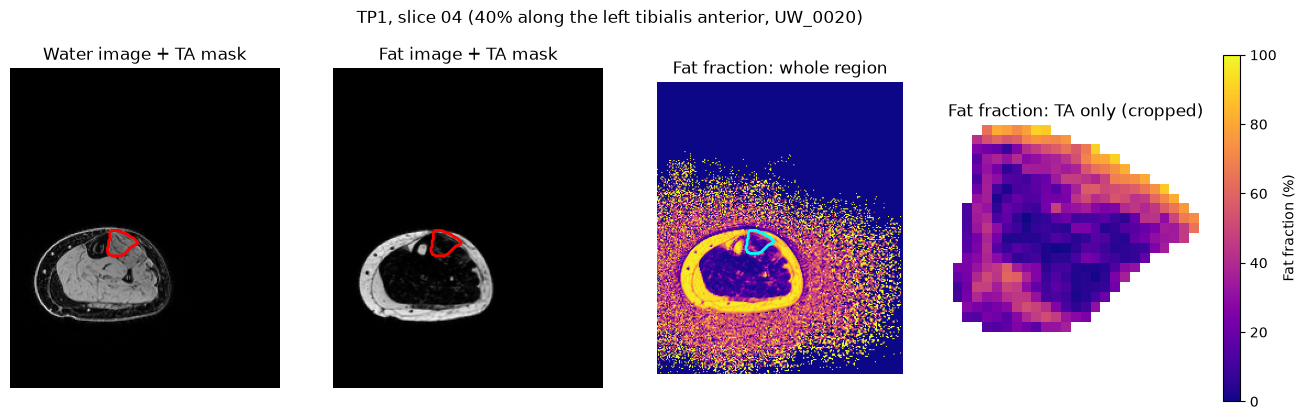

In [22]:
y_pixels, x_pixels = np.where(mask)
y0, y1 = y_pixels.min(), y_pixels.max() + 1
x0, x1 = x_pixels.min(), x_pixels.max() + 1
fat_fraction_TA = fat_fraction_masked[y0:y1, x0:x1]

fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))

axes[0].imshow(water, cmap="gray")
axes[0].contour(mask, levels=[0.5], colors="red", linewidths=2)
axes[0].set_title("Water image + TA mask")

axes[1].imshow(fat, cmap="gray")
axes[1].contour(mask, levels=[0.5], colors="red", linewidths=2)
axes[1].set_title("Fat image + TA mask")

axes[2].imshow(fat_fraction_full, cmap="plasma", vmin=0, vmax=100)
axes[2].contour(mask, levels=[0.5], colors="cyan", linewidths=2)
axes[2].set_title("Fat fraction: whole region")

ta_image = axes[3].imshow(fat_fraction_TA, cmap="plasma", vmin=0, vmax=100)
axes[3].set_title("Fat fraction: TA only (cropped)")

for ax in axes:
    ax.axis("off")      # pixel axes omitted; 1 pixel = 1.12 mm in-plane
fig.colorbar(ta_image, ax=axes[2:], fraction=0.046, pad=0.04, label="Fat fraction (%)")
fig.suptitle("TP1, slice 04 (40% along the left tibialis anterior, UW_0020)")
plt.show()

**Figure 1 caption.** Water and fat signal images (grayscale, arbitrary signal units) and the fat-fraction map (0 to 100%, colorbar) for one mid-muscle slice. The red/cyan outline is the TA segmentation mask. The figure is included to confirm that the mask sits on the TA and to show how much non-muscle anatomy (subcutaneous fat, other muscles, bone) surrounds it. The TA-only panel shows that fat is unevenly distributed inside the muscle.

### Figure 2: Fat-fraction distribution, whole region versus TA only

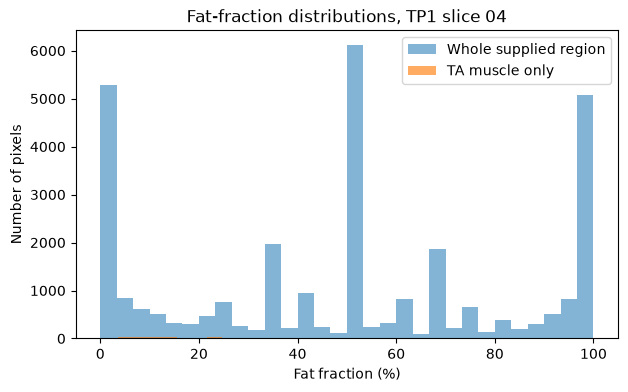

In [23]:
plt.figure(figsize=(7, 4))
plt.hist(whole_image_values, bins=30, alpha=0.55, label="Whole supplied region")
plt.hist(muscle_values, bins=30, alpha=0.65, label="TA muscle only")
plt.xlabel("Fat fraction (%)")
plt.ylabel("Number of pixels")
plt.title("Fat-fraction distributions, TP1 slice 04")
plt.legend()
plt.show()

**Figure 2 caption.** Histogram of fat fraction for all pixels with signal in the image half (blue) and for TA pixels only (orange). The whole-region mean is 48.6% but the TA mean is 29.9%, so including non-muscle pixels would overestimate fat in the muscle. The whole-region distribution also contains pixels at exactly 0% and 100%, which come from background and fat-only or water-only tissue rather than muscle. The TA-only distribution is broad and spans most of the 0 to 100% range, so a single mean does not describe it fully; the median and SD are reported alongside it for that reason.

### 4. Repeat for every sampled location and both visits

The calculation is wrapped in a function and applied to all eight slices for TP1 and TP2. For each slice we record the mean, median, SD, and number of TA pixels. The SD is the population SD (`np.nanstd`).

In [24]:
def calculate_fat_fraction(water, fat, mask):
    """Return a masked fat-fraction image in percent."""
    denominator = water + fat
    result = np.divide(fat, denominator,
                       out=np.zeros_like(fat, dtype=float),
                       where=denominator > 0) * 100
    result[~mask] = np.nan
    return result

results = []
for _, r in manifest.iterrows():
    w = np.load(DATA_DIR / r["water_file"])
    f = np.load(DATA_DIR / r["fat_file"])
    m = np.load(DATA_DIR / r["mask_file"]).astype(bool)
    ff = calculate_fat_fraction(w, f, m)
    results.append({
        "subject": r["subject"],
        "timepoint": r["timepoint"],
        "slice_id": r["slice_id"],
        "percent_along_muscle": r["percent_along_muscle"],
        "distance_from_muscle_start_mm": r["distance_from_muscle_start_mm"],
        "mean_fat_fraction_percent": np.nanmean(ff),
        "median_fat_fraction_percent": np.nanmedian(ff),
        "std_fat_fraction_percent": np.nanstd(ff),
        "n_muscle_pixels": int(m.sum()),
    })

results_df = pd.DataFrame(results)
results_df.round(2)

,subject,timepoint,slice_id,percent_along_muscle,distance_from_muscle_start_mm,mean_fat_fraction_percent,median_fat_fraction_percent,std_fat_fraction_percent,n_muscle_pixels
0,UW_0020,TP1,1,10,24.0,83.92,88.83,13.27,61
1,UW_0020,TP1,2,20,44.0,82.71,86.65,12.43,115
2,UW_0020,TP1,3,30,68.0,58.50,61.82,22.88,231
3,UW_0020,TP1,4,40,92.0,29.93,25.37,21.58,360
4,UW_0020,TP1,5,50,116.0,20.87,14.55,20.06,421
5,UW_0020,TP1,6,60,136.0,16.76,9.05,19.67,440
6,UW_0020,TP1,7,70,160.0,17.51,8.96,20.46,388
7,UW_0020,TP1,8,80,184.0,27.87,22.69,22.63,263
8,UW_0020,TP2,1,10,24.0,82.39,90.84,15.91,46
9,UW_0020,TP2,2,20,48.0,84.05,92.03,17.74,74


### Figure 3: Mean TA fat fraction along the muscle, TP1 versus TP2

The x-axis is the measured distance from the muscle start in mm, because the slices are not equally spaced in mm and the spacing differs slightly between visits.

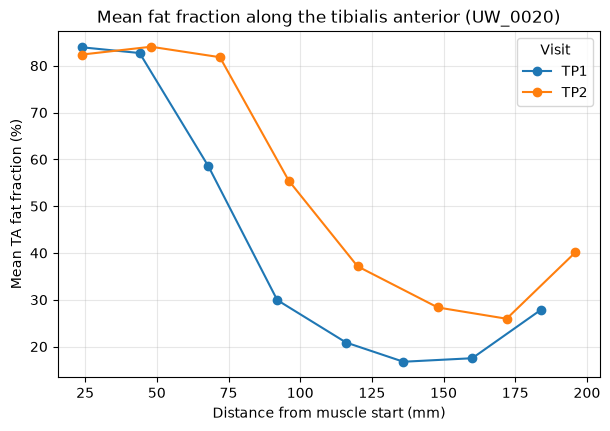

In [25]:
plt.figure(figsize=(7, 4.5))
for timepoint, group in results_df.groupby("timepoint"):
    group = group.sort_values("distance_from_muscle_start_mm")
    plt.plot(group["distance_from_muscle_start_mm"],
             group["mean_fat_fraction_percent"],
             marker="o", label=timepoint)
plt.xlabel("Distance from muscle start (mm)")
plt.ylabel("Mean TA fat fraction (%)")
plt.title("Mean fat fraction along the tibialis anterior (UW_0020)")
plt.legend(title="Visit")
plt.grid(True, alpha=0.3)
plt.show()

**Figure 3 caption.** Mean fat fraction inside the TA mask at eight locations along the muscle, for each visit. It is included to show that fat fraction varies strongly along the muscle (it is high near both ends and lowest in the middle) and to compare visits. TP2 lies above TP1 at most locations. Because this is one subject at two visits, the plot illustrates the method and is not evidence of a population trend.

### 5. Compare visits at matching percent locations and save a summary file

The distance in mm differs between visits (for example 116 mm vs 120 mm at 50%), so visits are compared at the same **percent location** along the muscle. A change in MRI fat fraction indicates a change in muscle composition, but it is not by itself evidence that function improved or worsened.

In [26]:
comparison = results_df.pivot(index="percent_along_muscle",
                              columns="timepoint",
                              values="mean_fat_fraction_percent")
comparison["change_TP2_minus_TP1"] = comparison["TP2"] - comparison["TP1"]
display(comparison.round(2))

output_file = Path("TA_fat_fraction_summary.csv")
results_df.to_csv(output_file, index=False)
print(f"Saved {output_file}")

timepoint,TP1,TP2,change_TP2_minus_TP1
percent_along_muscle,,,
10,83.92,82.39,-1.53
20,82.71,84.05,1.34
30,58.50,81.82,23.32
40,29.93,55.45,25.52
50,20.87,37.15,16.28
60,16.76,28.35,11.59
70,17.51,25.95,8.43
80,27.87,40.14,12.27


Saved TA_fat_fraction_summary.csv




**Subject and visits.** This project analyzes MRI data from one subject, UW_0020, at two visits (TP1 and TP2) [1]. The data come from a small teaching sample derived from a larger natural-history study of 34 individuals with FSHD followed for about two years. 

**Tibialis anterior MRI data.** The sample contains cross-sectional images of the left tibialis anterior (TA) muscle. There are eight samples per visit, 16 in total. Each is stored as a NumPy array (`.npy`) with 266 x 224 pixels. The arrays contain only the half of each in-plane image that includes the TA, which removes the unrelated side while keeping the surrounding anatomy and background [1]. In-plane pixel spacing is 1.116 x 1.116 mm, and the slice spacing is 4.0 mm [2].

**Water and fat images.** Each sample has a paired water image (`TPx_slice_##_water.npy`) and fat image (`TPx_slice_##_fat.npy`). They show the signal from water-containing tissue and from fat separately for the same anatomy. Fat fraction was not provided: it is calculated from these two images as fat / (water + fat) x 100 [1]. 

**TA segmentation mask.** Each sample also has a binary mask (`TPx_slice_##_mask.npy`), where 1 marks TA pixels and 0 marks everything else [1]. The dataset information file records label 59 as the TA segmentation label [2]. The mask was supplied with the data, and we did not segment the muscle ourselves. 

**Sampled locations along the muscle.** Slices were sampled at 10%, 20%, 30%, 40%, 50%, 60%, 70%, and 80% of the way along the muscle. The distance from the muscle start in mm is given for each slice and is not evenly spaced. The mm distances also differ between visits because the position of each percent location differs. Visits are therefore compared at matching percent locations, and plots use the mm distance [1][3].

The values keep the original MRI signal units, which are arbitrary scanner intensity units rather than physical units [1]. Water and fat signals have no meaningful absolute scale on their own, but their ratio is unitless, so fat fraction is a percentage from 0% (no fat signal) to 100% (all fat signal). Higher fat fraction in the TA indicates more of the muscle has been replaced by fat, which is a hallmark of FSHD progression. The sample used here contains only MRI arrays and the metadata table (visit, slice, percent location, distance, z-index, and file names) [1]. It has no clinical, biomarker, or functional measurements.

The data were provided by the course instructors as a teaching dataset, and the README documents its contents [1]. 

**References for this section**
1. README.md, "Student MRI sample: tibialis anterior at two visits," course data folder `FSHD_TA_MRI_data_0020_TP1_TP2`.
2. dataset_info.json and slice_info.csv, same data folder.
3. Course example notebook, `FSHD_TA_MRI_example_notebook.ipynb`.

## Interpolation Analysis: [Tripp]

Explain how interpolation was used to estimate fat fraction or another measurement at a location between sampled points along the tibialis anterior.

Include:

- The variable used to define location along the muscle, such as distance in millimeters or percentage of muscle length
- The sampled locations used as inputs to the interpolation
- The interpolation method and Python code used
- A plot showing the measured values and the interpolated estimate(s)
- Why interpolation is an estimate rather than a new measurement
- The assumptions made about how the measurement changes between sampled locations
- Whether the estimate is within the range of sampled data or represents extrapolation
- Any limitations or sources of uncertainty in the interpolated result

### Interpolation Analysis and Code Explanation

The purpose of this code was to analyze changes in MRI fat fraction in the right tibialis anterior (TA) muscle using the FSHD dataset. We used Python libraries, including pandas and NumPy, to load and organize the data, Matplotlib to create graphs, and SciPy to perform interpolation. Because participants did not all attend their visits at exactly the same times, we used interpolation to estimate fat fraction at common time points so their results could be compared more consistently.

The code identifies the earliest Year 1 and Year 2 visit times across participants and uses linear interpolation for the first common time point and quadratic interpolation for the second. Linear interpolation estimates a value between two measurements by assuming a straight-line change, while quadratic interpolation uses three measurements to estimate a curved trend. The code also checks for missing measurements and whether enough data are available before calculating estimates.

Finally, the code summarizes the results, plots the average fat fraction over time, displays the distribution of changes from baseline, and saves the interpolated results to a CSV file for further analysis. We used this approach to investigate whether MRI fat fraction increased over time and whether it could be a useful exploratory endpoint for tracking FSHD progression. However, interpolation produces estimates rather than actual measurements at the common time points, so the results should be interpreted cautiously and considered alongside muscle strength and functional measurements.

Dataset shape: (34, 46)
Columns: ['subject_id', 'sex', 'age_baseline', 'd4z4', 'dux4_signature_baseline_R', 'dux4_signature_baseline_L', 'lag_months_baseline', 'lag_months_y1', 'lag_months_y2', 'ff_baseline_R', 'ff_y1_R', 'ff_y2_R', 'ff_baseline_L', 'ff_y1_L', 'ff_y2_L', 'fvar_baseline_R', 'fvar_y1_R', 'fvar_y2_R', 'fvar_baseline_L', 'fvar_y1_L', 'fvar_y2_L', 'stir_quant_baseline_R', 'stir_quant_y1_R', 'stir_quant_baseline_L', 'stir_quant_y1_L', 'dorsiflexion_qmt_R_baseline', 'dorsiflexion_qmt_R_y1', 'dorsiflexion_qmt_R_y2', 'dorsiflexion_qmt_L_baseline', 'dorsiflexion_qmt_L_y1', 'dorsiflexion_qmt_L_y2', 'tug_time_baseline', 'tug_time_y1', 'tug_time_y2', 'wr_10_baseline', 'wr_10_y1', 'wr_10_y2', 'ascend_4_baseline', 'ascend_4_y1', 'ascend_4_y2', 'descend_4_baseline', 'descend_4_y1', 'descend_4_y2', 'clinical_severity_score_baseline', 'clinical_severity_score_y1', 'clinical_severity_score_y2']

Common Year 1 time: 11.15 months
Common Year 2 time: 22.13 months

Interpolation results:


,subject,linear_T1,quadratic_T2,baseline
0,0,6.744922,6.725603,5.977253
1,1,NaN,NaN,10.825636
2,2,4.939927,4.494294,3.346368
3,3,6.616676,6.657714,5.476659
4,4,NaN,NaN,26.596680



Summary:
       baseline  linear_T1  quadratic_T2
count     34.00      31.00         24.00
mean      21.12      20.36         18.72
std       23.56      23.35         22.54
min        3.35       4.30          4.03
25%        6.17       6.64          6.71
50%        9.48       9.44          8.93
75%       24.07      15.85         14.33
max       78.08      74.52         72.98


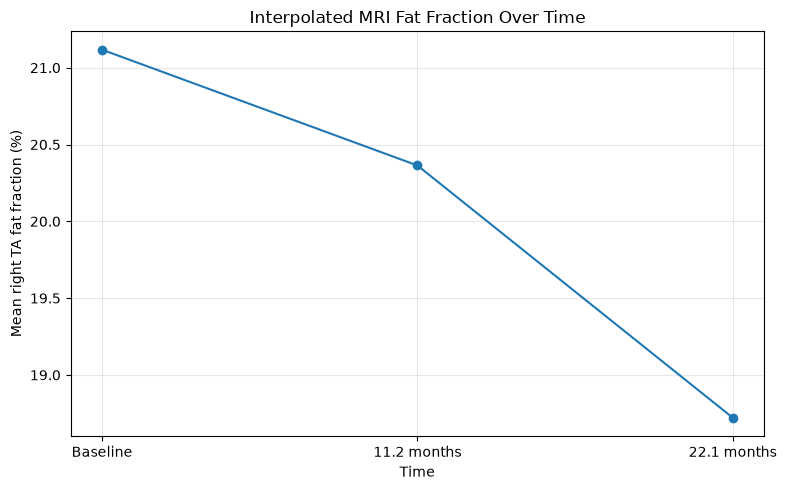

Saved FSHD_interpolation_results.csv
RIGHT TA FAT FRACTION CHANGE
--------------------------------
Participants with Year 1 estimates: 31
Mean change at T1: 0.93 percentage points
Median change at T1: 0.7 percentage points
Participants with Year 2 estimates: 24
Mean change at T2: 1.52 percentage points
Median change at T2: 1.16 percentage points


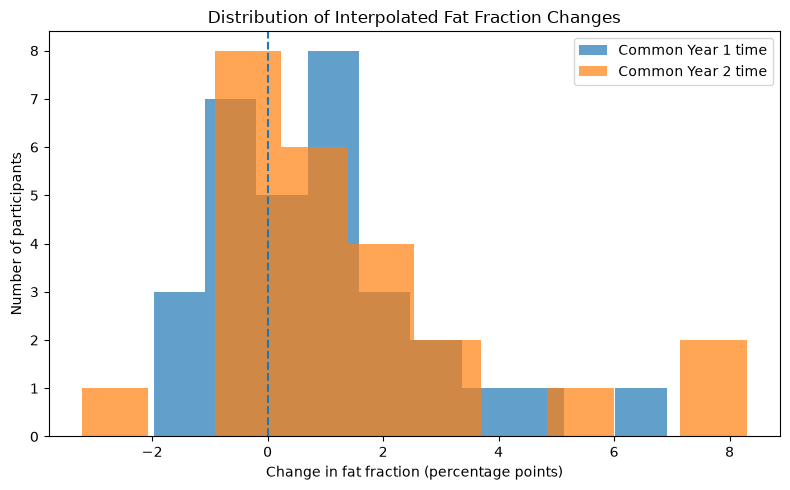

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from pathlib import Path

# Find and load the main dataset
matches = list(Path.cwd().rglob("Module2_FSHD_Dataset*.csv"))

if not matches:
    raise FileNotFoundError(
        "Could not find Module2_FSHD_Dataset.csv. "
        "Place the CSV in your project folder."
    )

df = pd.read_csv(matches[0])

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

# Common comparison times
T1 = df["lag_months_y1"].min()
T2 = df["lag_months_y2"].min()

print(f"\nCommon Year 1 time: {T1:.2f} months")
print(f"Common Year 2 time: {T2:.2f} months")

# Interpolate right tibialis anterior fat fraction
# Change these column names if your CSV uses different names.
required_columns = [
    "lag_months_baseline", "lag_months_y1", "lag_months_y2",
    "ff_baseline_R", "ff_y1_R", "ff_y2_R"
]

missing = [col for col in required_columns if col not in df.columns]

if missing:
    raise ValueError(
        f"Check the CSV column names. Missing columns: {missing}"
    )

results = []

for _, row in df.iterrows():
    times = np.array([
        row["lag_months_baseline"],
        row["lag_months_y1"],
        row["lag_months_y2"]
    ], dtype=float)

    values = np.array([
        row["ff_baseline_R"],
        row["ff_y1_R"],
        row["ff_y2_R"]
    ], dtype=float)

    # Keep only valid measurements
    valid = np.isfinite(times) & np.isfinite(values)
    times = times[valid]
    values = values[valid]

    # Sort visits by time
    order = np.argsort(times)
    times = times[order]
    values = values[order]

    result = {"subject": row.get("subject", row.name)}

    # Linear interpolation at T1
    if len(times) >= 2 and times[0] <= T1 <= times[-1]:
        linear = interp1d(times, values, kind="linear")
        result["linear_T1"] = float(linear(T1))
    else:
        result["linear_T1"] = np.nan

    # Quadratic interpolation at T2 requires three valid visits
    if len(times) >= 3 and times[0] <= T2 <= times[-1]:
        quadratic = interp1d(times, values, kind="quadratic")
        result["quadratic_T2"] = float(quadratic(T2))
    else:
        result["quadratic_T2"] = np.nan

    result["baseline"] = (
        values[0] if len(values) > 0 else np.nan
    )
    results.append(result)

interpolated = pd.DataFrame(results)

print("\nInterpolation results:")
display(interpolated.head())

print("\nSummary:")
print(interpolated[["baseline", "linear_T1",
                     "quadratic_T2"]].describe().round(2))

# Plot average fat fraction at the common time points
means = interpolated[
    ["baseline", "linear_T1", "quadratic_T2"]
].mean()

plt.figure(figsize=(8, 5))
plt.plot(
    ["Baseline", f"{T1:.1f} months", f"{T2:.1f} months"],
    means.values,
    marker="o"
)
plt.xlabel("Time")
plt.ylabel("Mean right TA fat fraction (%)")
plt.title("Interpolated MRI Fat Fraction Over Time")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Save results for the project
interpolated.to_csv("FSHD_interpolation_results.csv", index=False)
print("Saved FSHD_interpolation_results.csv")

# Comparing MRI Fat Fraction CHanges

# %% Compare MRI Fat Fraction Changes

baseline = interpolated["baseline"]
year1 = interpolated["linear_T1"]
year2 = interpolated["quadratic_T2"]

change_year1 = year1 - baseline
change_year2 = year2 - baseline

print("RIGHT TA FAT FRACTION CHANGE")
print("--------------------------------")
print("Participants with Year 1 estimates:",
      change_year1.notna().sum())
print("Mean change at T1:",
      round(change_year1.mean(), 2), "percentage points")
print("Median change at T1:",
      round(change_year1.median(), 2), "percentage points")
print("Participants with Year 2 estimates:",
      change_year2.notna().sum())
print("Mean change at T2:",
      round(change_year2.mean(), 2), "percentage points")
print("Median change at T2:",
      round(change_year2.median(), 2), "percentage points")

# Show the distribution of changes
plt.figure(figsize=(8, 5))
plt.hist(change_year1.dropna(), alpha=0.7,
         label="Common Year 1 time")
plt.hist(change_year2.dropna(), alpha=0.7,
         label="Common Year 2 time")
plt.axvline(0, linestyle="--")
plt.xlabel("Change in fat fraction (percentage points)")
plt.ylabel("Number of participants")
plt.title("Distribution of Interpolated Fat Fraction Changes")
plt.legend()
plt.tight_layout()
plt.show()

## Conclusions:

Explain what your analysis suggests about measuring FSHD progression.

Discuss:

- Which MRI, biomarker, or functional measures changed most consistently
- Which measures appeared most sensitive to differences across muscle locations or visits
- Whether the measures could be useful as biomarkers or exploratory clinical-trial endpoints
- What additional evidence would be needed before using them to evaluate treatment effectiveness
- Potential ethical implications of selecting one measure over another, including patient relevance, accessibility, and the risk of overlooking meaningful changes in function

## Conclusions

MRI fat fraction appears to be a promising measure for tracking FSHD progression and could be useful as an exploratory endpoint in an early-phase clinical trial. In our interpolation analysis, the mean fat fraction change from baseline was approximately 0.93 percentage points at the first common time point and 1.52 percentage points at the second. These estimates were based on 31 participants at the first time point and 24 at the second. The results suggest that MRI fat fraction may help identify changes in muscle composition over time. However, these estimates depend on the available data and interpolation methods, so they should be interpreted cautiously. MRI measurements can also vary across locations within a muscle, making consistent muscle locations and comparable visits important when evaluating changes.

MRI fat fraction should be considered alongside functional measures, such as muscle strength and performance tests. While MRI can detect changes in muscle composition, it does not directly show whether a person has experienced a meaningful change in mobility, strength, or daily activities. Functional tests may capture these effects more directly. Biomarkers that were only measured at baseline also cannot establish how those biomarkers change as the disease progresses. Therefore, our analysis does not establish that one measure is best for every aspect of FSHD progression; combining imaging and functional outcomes may provide a more complete picture.

These measures could be useful for monitoring disease progression and helping researchers select endpoints for future clinical trials. However, our analysis uses natural-history data rather than testing a treatment, so changes over time do not demonstrate that a treatment is effective. Larger studies and clinical trials would be needed to confirm that the measures are reliable, detect meaningful changes, and respond to treatment. Researchers should also consider the ethical implications of endpoint selection. MRI and specialized testing may be expensive or difficult for some patients to access, while measures focused only on muscle composition may overlook improvements or declines that affect daily life. The most appropriate endpoints should therefore be scientifically reliable, practical for participants, and relevant to the outcomes that matter to people living with FSHD.

Overall, MRI fat fraction, dorsiflexion strength, the TUG test, and the Clinical Severity Score appear to be reasonable candidate endpoints for further investigation in FSHD clinical trials because they assess different aspects of disease progression. However, additional research is needed to establish their reliability, sensitivity to meaningful changes, and ability to detect treatment effects. Using a combination of these measures may provide a more comprehensive assessment than relying on any single endpoint alone.

## Limitations and Future Work:

 ### Limitations

**Sample size and generalizability.** The MRI analysis uses a single subject (UW_0020), one muscle (left TA), and two visits, so it demonstrates the method but cannot support any claim about FSHD progression in general. The interpolation analysis uses the full cohort, but not every participant contributed: 31 had an estimate at the first common time point and 24 at the second, because the quadratic estimate needs three valid visits. Participants with missing visits may differ from those with complete data, which could bias the averages in either direction. The cohort is also small for a disease with large differences between people.

**Available visits.** Participants were followed for about two years with a baseline, Year 1, and Year 2 visit, so we cannot see long-term progression or whether change is steady or comes in bursts. Visit timing was irregular. We moved everyone to common time points (the earliest Year 1 and Year 2 lag times in the cohort), but the values at those times are estimates, not measurements. The quadratic estimate passes exactly through three points, so it cannot be checked against any independent data and could overshoot if one visit value is noisy. For many participants the common time points fall earlier than their real visits, so the estimated change reflects less time than they actually had.

**MRI measurements.** Fat fraction here is a simple signal ratio from the supplied water and fat images, and we did not correct for scanner effects such as noise, field inhomogeneity, or relaxation differences between water and fat. We did not measure scan-rescan reliability, so we cannot say how much of a small change, such as the roughly 1 to 1.5 percentage point average changes we found, is real change versus measurement variation. Only eight slices between 10% and 80% of the muscle length were available, so the ends of the muscle are not covered. Comparing visits at the same percent location assumes the slices line up anatomically, which may not be exact because positions in mm differ between visits. The mean also summarizes a broad pixel distribution (Figure 2), so it can hide patchy fat replacement.

**MRI availability.** With MRI testing being high cost, MRI accessibility is not guaranteed between patients. Some rural states with fewer hospitals may not have access to the same testing other states do.

**Segmentation.** The TA masks were provided with the data, and we did not create or validate them. We only checked one slice by eye (Figure 1). Pixels at the mask edge mix muscle with fat or other tissue, and small differences in how the muscle was outlined at each visit could change the mean fat fraction and the pixel counts.

**Biomarkers and functional measures.** The teaching sample contains only MRI arrays, with no strength, performance, or clinical data, so we could not test whether MRI changes match changes in function. Our code only analyzes MRI fat fraction. We did not compute change statistics for dorsiflexion strength, the TUG test, or the Clinical Severity Score, so our comments on those measures in the Conclusions come from their general role and not from our own comparison. Biomarkers measured only at baseline cannot show change over time.

**Analysis methods.** We report means, medians, and SD but no confidence intervals, statistical tests, or effect sizes such as the standardized response mean, so we cannot say whether the average change is statistically distinguishable from zero or how consistent it is between people. The interpolation analysis was run on the right TA and the MRI methodology on the left TA of one subject, so the two parts are not directly linked. Natural-history data also cannot tell us whether a measure would respond to a treatment.

### Future Work

With more time or data, we would first analyze fat fraction for all 34 participants from the image data, using several muscles (for example both TAs and other leg or shoulder muscles) instead of one. Adding more timepoints would let us fit change over time directly and reduce our reliance on interpolation. We would check the segmentations for consistency between visits and compare automatic and manual outlines. To judge whether the changes are meaningful, we would measure scan-rescan variability and add confidence intervals and effect sizes, so the sensitivity of each candidate endpoint can be compared fairly. We would then compare MRI fat fraction against dorsiflexion strength, TUG, and the Clinical Severity Score for the same people to see whether imaging changes track function. Finally, data from a treated group or a trial would be needed to test whether any of these measures responds to treatment.

## AI Usage Statement:
We used Claude Code to help with the Methods Analysis section and debugging code throughout. It was also used to help with clearly labeling the generated figures and fixing formatting issues.

ChatGPT 6 was used to assist with syntax and understanding of interpolation analysis, debugging, and graph generation code. The internal VS code AI agent was utilized to help with indentation-related errors.

## GitHub Repository Link:
https://github.com/tripphilderbrand/BME2315_Module2-fixed-


## References:


## NOTES FROM YOUR TEAM: 
*This is where our team is taking notes and recording activity.*

## QUESTIONS FOR YOUR TA: 
I have no idea why the formatting is like this, I am working on fixing it. I will come to office hours to get help with this!